In [145]:
!pip install grad-cam

In [146]:
import pandas as pd
import os
import cv2
import torch
import torchvision
import torch.nn.functional as functional
from torch.utils.data import DataLoader, TensorDataset, Dataset,  WeightedRandomSampler
import torch.nn as nn
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
import torchvision.transforms as transforms
from torchvision import models
from pytorch_grad_cam import GradCAM, GradCAMPlusPlus, LayerCAM, ScoreCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image


In [147]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(device)

cuda:0


(2560, 1920)


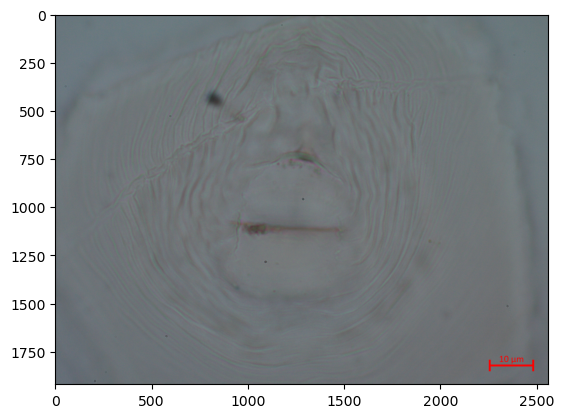

In [148]:
def get_image(path):
    with open(os.path.abspath(path), 'rb') as f:
        with Image.open(f) as img:
            return img.convert('RGB') 
        
img = get_image('/home/dbtproject/barsha/Image/test_set/Class2_Javanica/Meloidogyne javanica_22.tiff')
plt.imshow(img)
print(img.size)

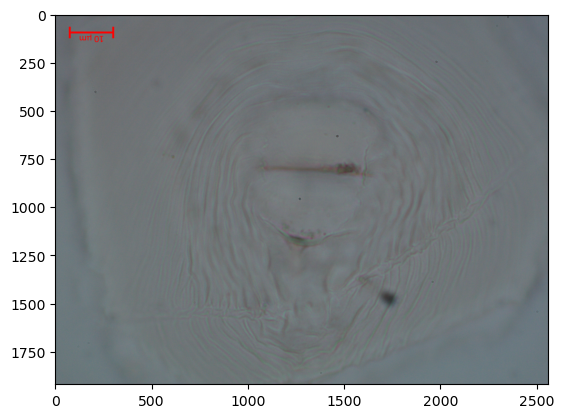

In [149]:
img_r = get_image('/home/dbtproject/barsha/Image/test_set/Class0_Graminicola/D-30_PP_4.tiff')
img_r = img.rotate(180, expand = True)
plt.imshow(img_r)


In [150]:
img_transform = transforms.Compose([
    transforms.Resize(232),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])
input_tensor = img_transform(img).unsqueeze(0)
input_tensor = input_tensor.to(device)
print(input_tensor)


tensor([[[[-0.3027, -0.2684, -0.2856,  ..., -0.3369, -0.4054, -0.4226],
          [-0.3027, -0.2856, -0.2684,  ..., -0.3541, -0.3712, -0.4054],
          [-0.3198, -0.3027, -0.2684,  ..., -0.3369, -0.3541, -0.3883],
          ...,
          [-0.3198, -0.3027, -0.3027,  ..., -0.2684, -0.2856, -0.2856],
          [-0.3198, -0.3027, -0.3198,  ..., -0.2856, -0.3027, -0.3027],
          [-0.3027, -0.3198, -0.3198,  ..., -0.2684, -0.3027, -0.3198]],

         [[ 0.1001,  0.1001,  0.1001,  ..., -0.0399, -0.0399, -0.0574],
          [ 0.1001,  0.1001,  0.1001,  ..., -0.0399, -0.0399, -0.0399],
          [ 0.1001,  0.1001,  0.1001,  ..., -0.0399, -0.0399, -0.0574],
          ...,
          [-0.0399, -0.0574, -0.0574,  ..., -0.1099, -0.1099, -0.1099],
          [-0.0574, -0.0574, -0.0399,  ..., -0.0924, -0.1099, -0.1275],
          [-0.0749, -0.0574, -0.0574,  ..., -0.1099, -0.1099, -0.1099]],

         [[ 0.4439,  0.4265,  0.4265,  ...,  0.2522,  0.2348,  0.2173],
          [ 0.4265,  0.4439,  

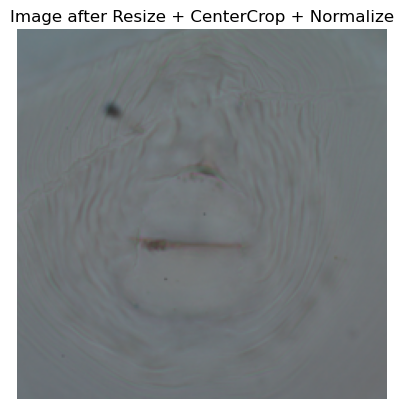

(224, 224, 3)


In [151]:
tensor_img = input_tensor.squeeze(0).cpu()
mean = torch.tensor([0.485, 0.456, 0.406]).view(3,1,1)
std  = torch.tensor([0.229, 0.224, 0.225]).view(3,1,1)

tensor_img = tensor_img * std + mean

img_np = tensor_img.permute(1, 2, 0).numpy()
img_np = np.clip(img_np, 0, 1)

plt.imshow(img_np)
plt.axis("off")
plt.title("Image after Resize + CenterCrop + Normalize")
plt.show()

print(img_np.shape)

In [152]:
input_tensor_r = img_transform(img_r).unsqueeze(0)
input_tensor_r = input_tensor_r.to(device)
print(input_tensor_r)

tensor([[[[-0.3198, -0.3198, -0.3027,  ..., -0.3027, -0.3198, -0.3198],
          [-0.2856, -0.3027, -0.3027,  ..., -0.3027, -0.3198, -0.3027],
          [-0.2856, -0.2856, -0.2856,  ..., -0.2684, -0.3027, -0.3027],
          ...,
          [-0.4054, -0.3883, -0.3541,  ..., -0.2684, -0.2684, -0.3027],
          [-0.4226, -0.4054, -0.3712,  ..., -0.3027, -0.2684, -0.2856],
          [-0.4226, -0.4226, -0.4054,  ..., -0.3027, -0.2856, -0.2684]],

         [[-0.1099, -0.1099, -0.1099,  ..., -0.0399, -0.0574, -0.0574],
          [-0.1275, -0.1275, -0.1099,  ..., -0.0399, -0.0399, -0.0574],
          [-0.1275, -0.1099, -0.1099,  ..., -0.0574, -0.0574, -0.0574],
          ...,
          [-0.0749, -0.0574, -0.0399,  ...,  0.0826,  0.1001,  0.1001],
          [-0.0574, -0.0399, -0.0399,  ...,  0.0826,  0.1001,  0.1001],
          [-0.0574, -0.0574, -0.0399,  ...,  0.1001,  0.1001,  0.1001]],

         [[ 0.1825,  0.1651,  0.1651,  ...,  0.2696,  0.2696,  0.2522],
          [ 0.1651,  0.1825,  

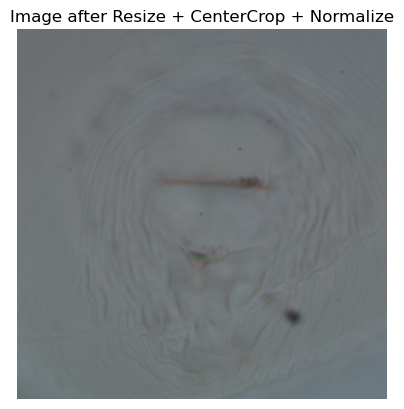

(224, 224, 3)


In [153]:
tensor_img_r = input_tensor_r.squeeze(0).cpu()
mean = torch.tensor([0.485, 0.456, 0.406]).view(3,1,1)
std  = torch.tensor([0.229, 0.224, 0.225]).view(3,1,1)

tensor_img_r = tensor_img_r * std + mean

img_np_r = tensor_img_r.permute(1, 2, 0).numpy()
img_np_r = np.clip(img_np_r, 0, 1)

plt.imshow(img_np_r)
plt.axis("off")
plt.title("Image after Resize + CenterCrop + Normalize")
plt.show()

print(img_np_r.shape)

In [154]:
# rgb_img = np.array(img.resize(224)) / 255.0
# plt.imshow(rgb_img)
# rgb_img_r = np.array(img_r.resize((224, 224))) / 255.0
# rgb_img = np.transpose(
#     input_tensor[0].cpu().numpy(), (1, 2, 0)
# )
# rgb_img = (rgb_img - rgb_img.min()) / (rgb_img.max() - rgb_img.min())
# print(rgb_img.shape)


(np.float64(-0.5), np.float64(223.5), np.float64(223.5), np.float64(-0.5))

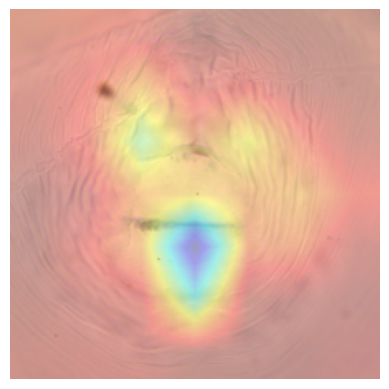

In [155]:

model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
in_features = model.fc.in_features
model.fc = nn.Linear(in_features, 3)
model.load_state_dict(torch.load("resnet50_weights_new_RI.pth", map_location=device))
model.eval().to(device)
target_layers = [model.layer4[-1]]
# We have to specify the target we want to generate the CAM for.
with torch.no_grad():
    outputs = model(input_tensor)
    pred_class = outputs.argmax(dim=1).item()

targets = [ClassifierOutputTarget(pred_class)]


# Construct the CAM object once, and then re-use it on many images.
with GradCAMPlusPlus(model=model, target_layers=target_layers) as cam:
  # You can also pass aug_smooth=True and eigen_smooth=True, to apply smoothing.
  grayscale_cam = cam(input_tensor=input_tensor, targets=targets, aug_smooth=False, eigen_smooth=False)
  # In this example grayscale_cam has only one image in the batch:
  grayscale_cam = grayscale_cam[0, :]
  cam_image = show_cam_on_image(img_np, grayscale_cam, use_rgb=True,image_weight=0.8)
  cam_image = cv2.cvtColor(cam_image, cv2.COLOR_RGB2BGR)
  # You can also get the model outputs without having to redo inference
  model_outputs = cam.outputs

plt.imshow(cam_image)
plt.axis("off")



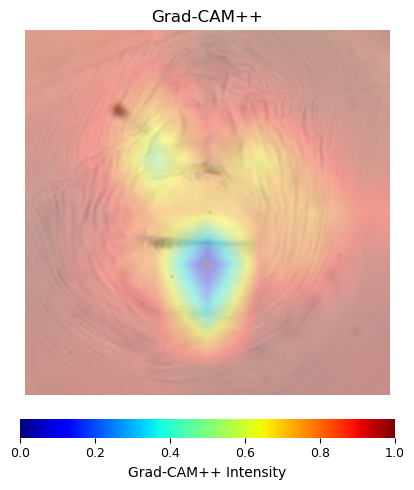

In [156]:
import matplotlib.pyplot as plt
import matplotlib as mpl

# -----------------------------
# Plot Grad-CAM++ with colorbar
# -----------------------------
fig, ax = plt.subplots(figsize=(5, 5))

# Show the Grad-CAM++ overlay image
ax.imshow(cam_image)
ax.axis("off")
ax.set_title("Grad-CAM++", fontsize=12)

# ---- Create a mappable linked to grayscale_cam ----
norm = mpl.colors.Normalize(vmin=0.0, vmax=1.0)
sm = mpl.cm.ScalarMappable(norm=norm, cmap='jet')  # same cmap as show_cam_on_image
sm.set_array([])

# ---- Horizontal colorbar under the image ----
cbar = fig.colorbar(
    sm,
    ax=ax,
    orientation='horizontal',
    fraction=0.046,   # thickness of bar
    pad=0.06          # distance from image
)

cbar.set_label("Grad-CAM++ Intensity", fontsize=10)
cbar.ax.tick_params(labelsize=9)
cbar.outline.set_visible(False)

plt.tight_layout()
plt.show()


In [157]:
# original_img = np.array(img)
# orig_h, orig_w = original_img.shape[:2]

original_img = np.array(img)/ 255.0
orig_h, orig_w = original_img.shape[:2]


Original image shape: (1920, 2560, 3)
Grayscale CAM shape: (224, 224)


Text(0.5, 1.0, 'Grad-CAM++ on Original Image')

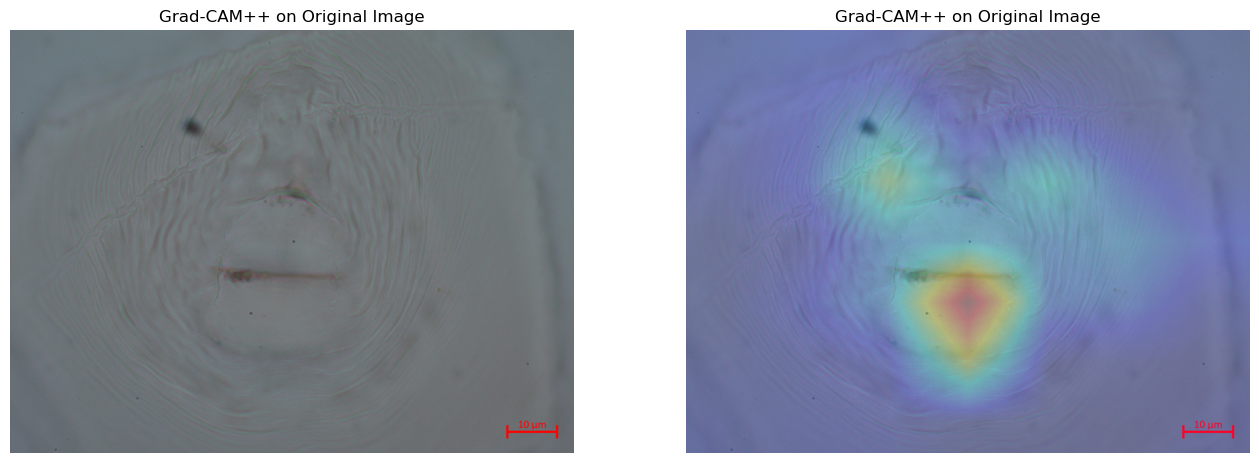

In [158]:
print("Original image shape:", original_img.shape)
print("Grayscale CAM shape:", grayscale_cam.shape)
cam_resized = cv2.resize(grayscale_cam, (orig_w, orig_h), interpolation=cv2.INTER_LINEAR)
# cam_resized = np.clip(cam_resized, 0, 1)

final_overlay = show_cam_on_image(original_img, cam_resized, use_rgb=True, image_weight=0.80)

plt.figure(figsize = (16,12))

plt.subplot(1,2,1)
plt.imshow(original_img)
plt.axis("off")
plt.title("Grad-CAM++ on Original Image")

plt.subplot(1,2,2)
plt.imshow(final_overlay)
plt.axis("off")
plt.title("Grad-CAM++ on Original Image")


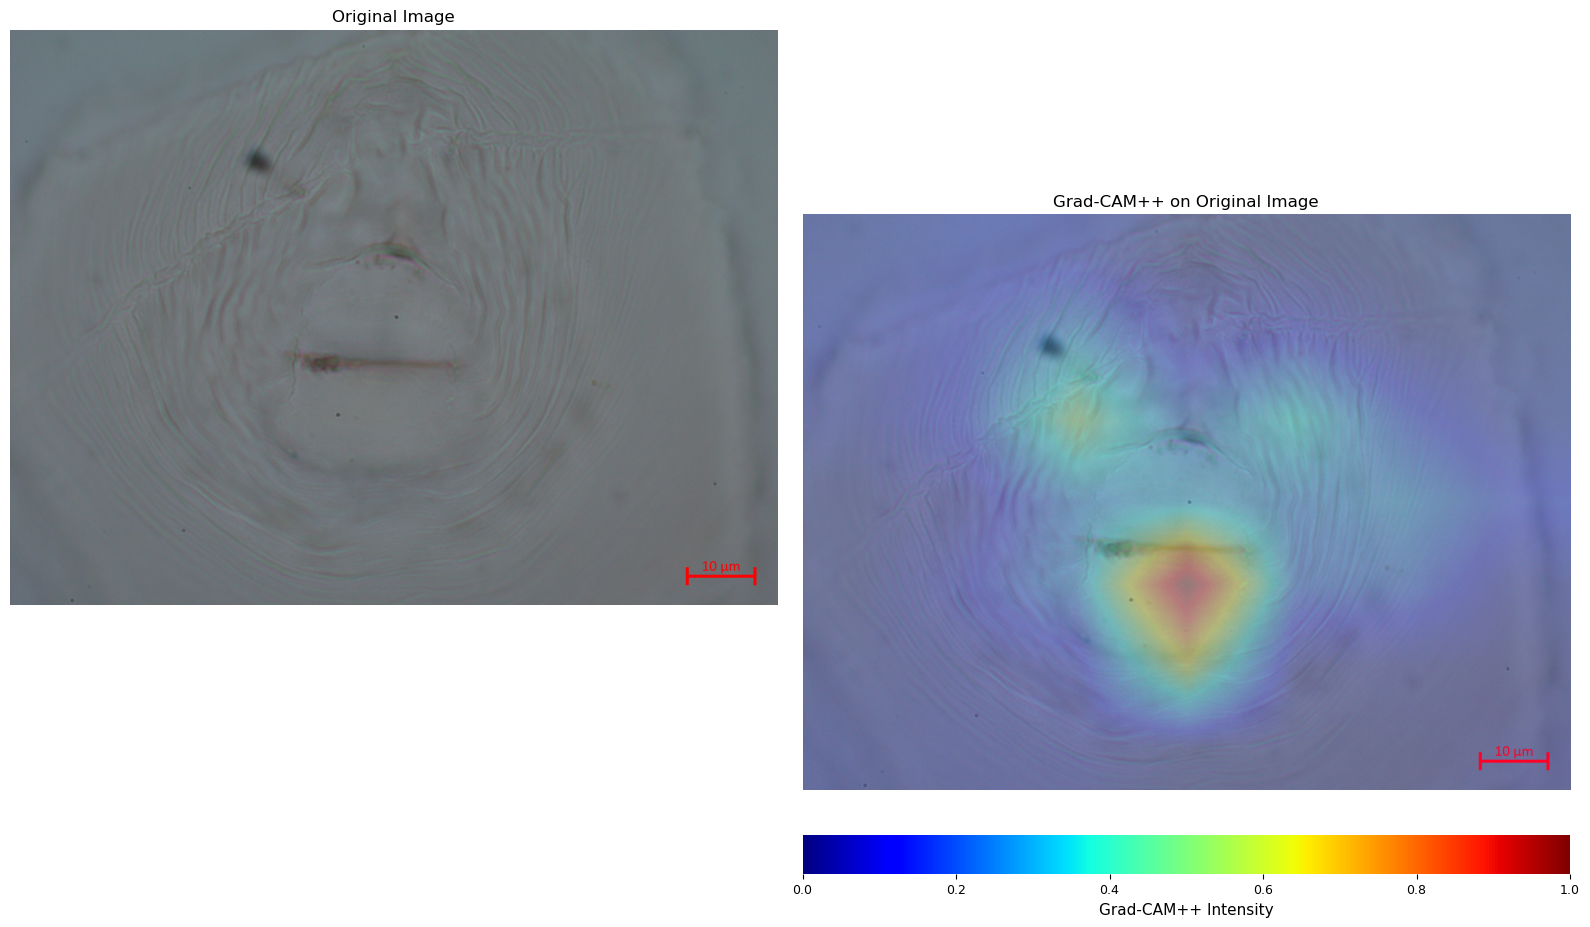

In [ ]:
import matplotlib.pyplot as plt
import matplotlib as mpl

plt.figure(figsize=(16, 12))


plt.subplot(1, 2, 1)
plt.imshow(original_img)
plt.axis("off")
plt.title("Original Image")


ax = plt.subplot(1, 2, 2)
ax.imshow(final_overlay)
ax.axis("off")
ax.set_title("Grad-CAM++ on Original Image")

norm = mpl.colors.Normalize(vmin=0.0, vmax=1.0)
sm = mpl.cm.ScalarMappable(norm=norm, cmap='jet')  # same colormap as CAM
sm.set_array([])

cbar = plt.colorbar(
    sm,
    ax=ax,
    orientation='horizontal',
    fraction=0.046,   # thickness of bar
    pad=0.04          # distance below image
)

cbar.set_label("Grad-CAM++ Intensity", fontsize=11)
cbar.ax.tick_params(labelsize=9)
cbar.outline.set_visible(False)

plt.tight_layout()
plt.show()



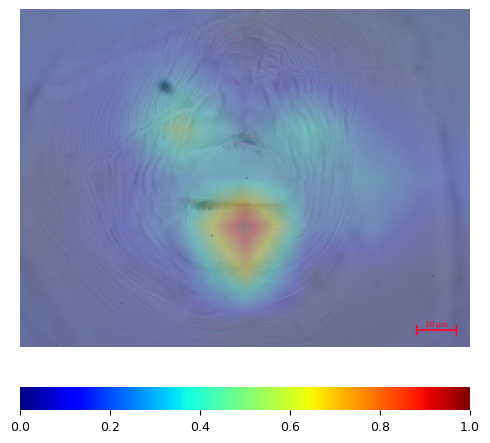

(1920, 2560, 3)


In [160]:
from mpl_toolkits.axes_grid1 import make_axes_locatable

fig, ax = plt.subplots(figsize=(5, 5))

# Show the Grad-CAM++ overlay image
ax.imshow(final_overlay)
ax.axis("off")
# ax.set_title("Grad-CAM++", fontsize=12)

# ---- Create a mappable linked to grayscale_cam ----
norm = mpl.colors.Normalize(vmin=0.0, vmax=1.0)
sm = mpl.cm.ScalarMappable(norm=norm, cmap='jet')  # same cmap as show_cam_on_image
sm.set_array([])

divider = make_axes_locatable(ax)
cax = divider.append_axes(
    "bottom",
    size="7%",
    pad=0.4
)


# ---- Horizontal colorbar under the image ----

cbar = fig.colorbar(
    sm,
    cax=cax,
    orientation='horizontal',
    fraction=0.046,   # thickness of bar
    pad=0.06          # distance from image
)

cbar.ax.tick_params(labelsize=9)
cbar.outline.set_visible(False)

plt.tight_layout()
plt.show()
plt.show()

print(final_overlay.shape)

(np.float64(-0.5), np.float64(223.5), np.float64(223.5), np.float64(-0.5))

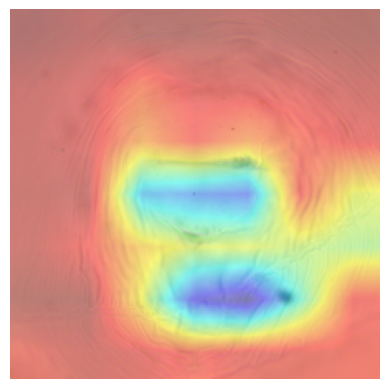

In [161]:
model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
in_features = model.fc.in_features
model.fc = nn.Linear(in_features, 3)
model.load_state_dict(torch.load("resnet50_weights_new_RI.pth", map_location=device))
model.eval().to(device)
target_layers = [model.layer4[-1]]
# We have to specify the target we want to generate the CAM for.
with torch.no_grad():
    outputs = model(input_tensor_r)
    pred_class = outputs.argmax(dim=1).item()

targets = [ClassifierOutputTarget(pred_class)]


# Construct the CAM object once, and then re-use it on many images.
with GradCAMPlusPlus(model=model, target_layers=target_layers) as cam:
  # You can also pass aug_smooth=True and eigen_smooth=True, to apply smoothing.
  grayscale_cam_r= cam(input_tensor=input_tensor_r, targets=targets, aug_smooth=False, eigen_smooth=False)
  # In this example grayscale_cam has only one image in the batch:
  grayscale_cam_r = grayscale_cam_r[0, :]
  cam_image_r = show_cam_on_image(img_np_r, grayscale_cam_r, use_rgb=True, image_weight=0.7)
  cam_image_r = cv2.cvtColor(cam_image_r, cv2.COLOR_RGB2BGR)
  # You can also get the model outputs without having to redo inference
  model_outputs = cam.outputs

plt.imshow(cam_image_r)
plt.axis("off")


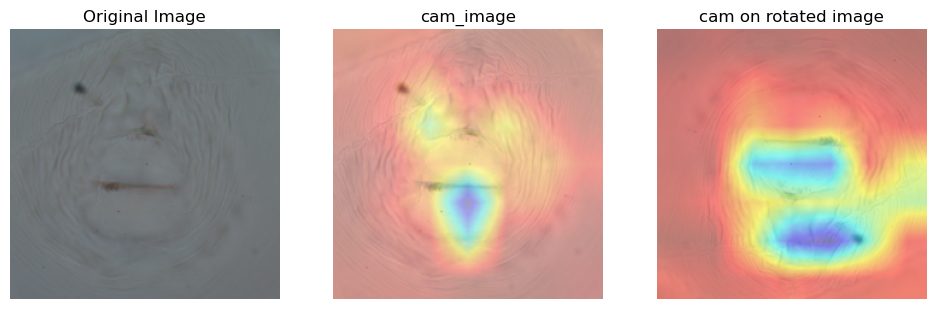

In [162]:
# from pytorch_grad_cam import GuidedBackpropReLUModel
# from pytorch_grad_cam.utils.image import (
#     show_cam_on_image, deprocess_image, preprocess_image
# )
#  gb_model = GuidedBackpropReLUModel(model=model, device=device)
# gb = gb_model(input_tensor, target_category=pred_class)

# cam_mask = cv2.merge([grayscale_cam, grayscale_cam, grayscale_cam])
# cam_gb = deprocess_image(cam_mask * gb)
# result = deprocess_image(gb)

plt.figure(figsize=(16, 4))

plt.subplot(1, 4, 1)
plt.title("Original Image")
plt.imshow(img_np)
plt.axis("off")

plt.subplot(1, 4, 2)
plt.title("cam_image")
plt.imshow(cam_image)
plt.axis("off")

plt.subplot(1, 4, 3)
plt.title("cam on rotated image")
plt.imshow(cam_image_r)
plt.axis("off")

# plt.subplot(1, 4, 4)
# plt.title("Guided Grad-CAM")
# plt.imshow(cam_gb)
# plt.axis("off")

plt.show()


In [114]:
# cam_map = grayscale_cam.copy()
# cam_map = (cam_map - cam_map.min()) / (cam_map.max() - cam_map.min() + 1e-8)

# cam_map_r = grayscale_cam_r.copy()
# cam_map_r = (cam_map - cam_map.min()) / (cam_map.max() - cam_map.min() + 1e-8)

# threshold = np.percentile(cam_map, 85)   # top 15% CAM activations
# thres = np.percentile(cam_map_r, 85)
# # threshold = 0.2
# binary_mask = (cam_map >= threshold).astype(np.uint8)
# binary_mask_r = (cam_map_r>= thres).astype(np.uint8)

# kernel = np.ones((9, 9), np.uint8)
# binary_mask = cv2.morphologyEx(binary_mask, cv2.MORPH_CLOSE, kernel)
# binary_mask_r = cv2.morphologyEx(binary_mask_r, cv2.MORPH_CLOSE, kernel)

# num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(
#     binary_mask,
#     connectivity=8
# )

# num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(
#     binary_mask_r,
#     connectivity=8
# )

# orig_img = (rgb_img * 255).astype(np.uint8) if rgb_img.max() <= 1 else rgb_img.copy()
# rotated_img = (rgb_img_r * 255).astype(np.uint8) if rgb_img_r.max() <= 1 else rgb_img_r.copy()

# boxed_img = orig_img.copy()
# boxed_img_r = rotated_img.copy()

# for i in range(1, num_labels):  # skip background
#     x, y, w, h, area = stats[i]

#     if area < 200:   # remove tiny noise
#         continue

#     cv2.rectangle(
#         boxed_img,
#         (x, y),
#         (x + w, y + h),
#         (0, 255, 0),   
#         2
#     )
#     cv2.rectangle(
#         boxed_img_r,
#         (x, y),
#         (x + w, y + h),
#         (0, 255, 0),   
#         2
#     )

# plt.figure(figsize=(6, 6))
# plt.imshow(boxed_img)
# plt.axis("off")
# plt.title("Original Image with Grad-CAM Bounding Boxes")
# plt.show()

# plt.figure(figsize=(6, 6))
# plt.imshow(boxed_img_r)
# plt.axis("off")
# plt.title("rotated Image with Grad-CAM Bounding Boxes")
# plt.show()


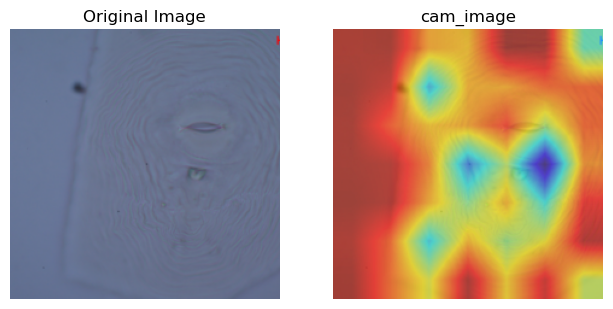

In [115]:
model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
in_features = model.fc.in_features
model.fc = nn.Linear(in_features, 3)
model.load_state_dict(torch.load("resnet50_weights_new_CC.pth", map_location=device))
model.eval().to(device)
target_layers = [model.layer4[-1]]
# We have to specify the target we want to generate the CAM for.
with torch.no_grad():
    outputs = model(input_tensor)
    pred_class = outputs.argmax(dim=1).item()

targets = [ClassifierOutputTarget(pred_class)]

with LayerCAM(model=model, target_layers=target_layers) as cam:
  # You can also pass aug_smooth=True and eigen_smooth=True, to apply smoothing.
  grayscale_cam_l = cam(input_tensor=input_tensor, targets=targets, aug_smooth=False, eigen_smooth=False)
  # In this example grayscale_cam has only one image in the batch:
  grayscale_cam_l = grayscale_cam_l[0, :]
  cam_image_l = show_cam_on_image(img_np, grayscale_cam_l, use_rgb=True)
  cam_image_l = cv2.cvtColor(cam_image_l, cv2.COLOR_RGB2BGR)
  # You can also get the model outputs without having to redo inference
  model_outputs = cam.outputs

plt.figure(figsize=(16, 4))

plt.subplot(1, 4, 1)

plt.title("Original Image")
plt.imshow(img_np)
plt.axis("off")

plt.subplot(1, 4, 2)
plt.title("cam_image")
plt.imshow(cam_image_l)
plt.axis("off")

plt.show()

(np.float64(-0.5), np.float64(223.5), np.float64(223.5), np.float64(-0.5))

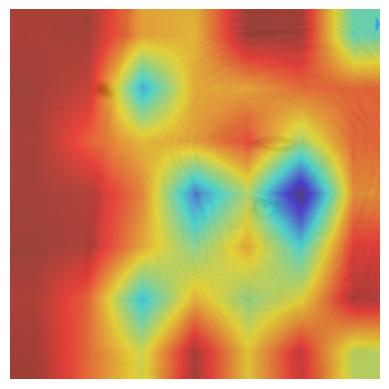

In [116]:
plt.imshow(cam_image_l)
plt.axis("off")

Original image shape: (1920, 2560, 3)
Grayscale CAM shape: (224, 224)


Text(0.5, 1.0, 'Grad-CAM++ on Original Image')

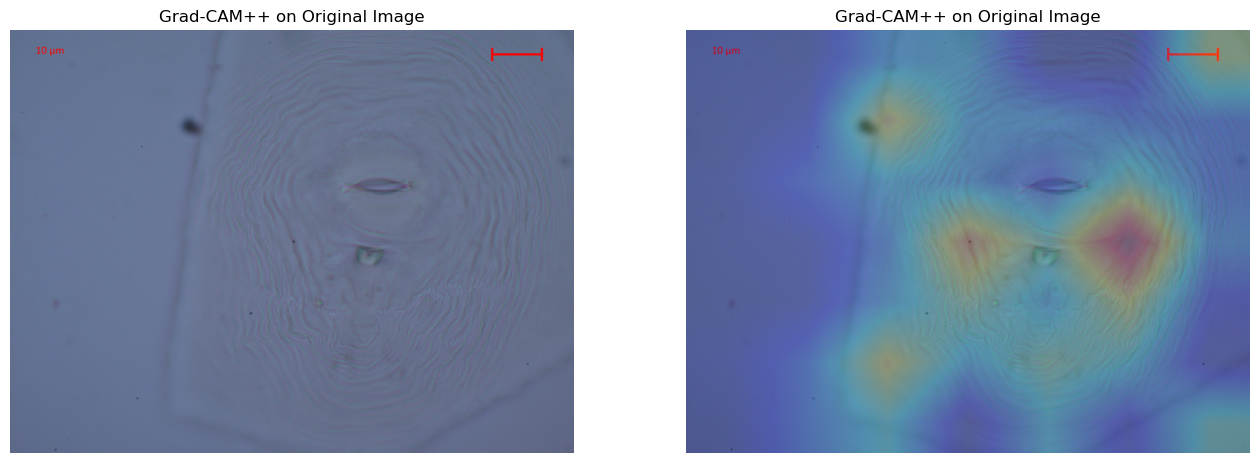

In [117]:
print("Original image shape:", original_img.shape)
print("Grayscale CAM shape:", grayscale_cam_l.shape)
cam_resized_l = cv2.resize(grayscale_cam_l, (orig_w, orig_h), interpolation=cv2.INTER_LINEAR)
# cam_resized = np.clip(cam_resized, 0, 1)

final_overlay_l = show_cam_on_image(original_img, cam_resized_l, use_rgb=True, image_weight=0.80)

plt.figure(figsize = (16,12))

plt.subplot(1,2,1)
plt.imshow(original_img)
plt.axis("off")
plt.title("Grad-CAM++ on Original Image")

plt.subplot(1,2,2)
plt.imshow(final_overlay_l)
plt.axis("off")
plt.title("Grad-CAM++ on Original Image")


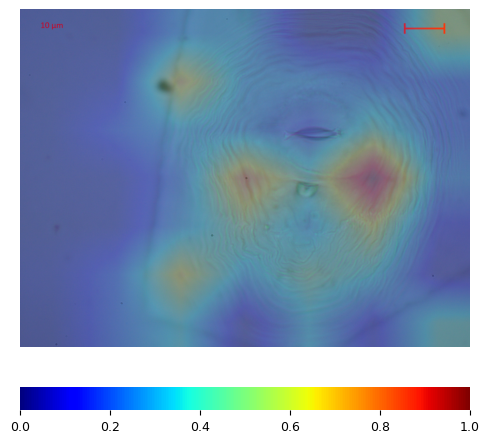

(1920, 2560, 3)


In [118]:
from mpl_toolkits.axes_grid1 import make_axes_locatable

fig, ax = plt.subplots(figsize=(5, 5))

# Show the Grad-CAM++ overlay image
ax.imshow(final_overlay_l)
ax.axis("off")
# ax.set_title("LayerCAM", fontsize=12)

# ---- Create a mappable linked to grayscale_cam ----
norm = mpl.colors.Normalize(vmin=0.0, vmax=1.0)
sm = mpl.cm.ScalarMappable(norm=norm, cmap='jet')  # same cmap as show_cam_on_image
sm.set_array([])

divider = make_axes_locatable(ax)
cax = divider.append_axes(
    "bottom",
    size="7%",
    pad=0.4
)


# ---- Horizontal colorbar under the image ----

cbar = fig.colorbar(
    sm,
    cax=cax,
    orientation='horizontal',
    fraction=0.046,   # thickness of bar
    pad=0.06          # distance from image
)

cbar.ax.tick_params(labelsize=9)
cbar.outline.set_visible(False)

plt.tight_layout()
plt.show()
plt.show()

print(final_overlay_l.shape)

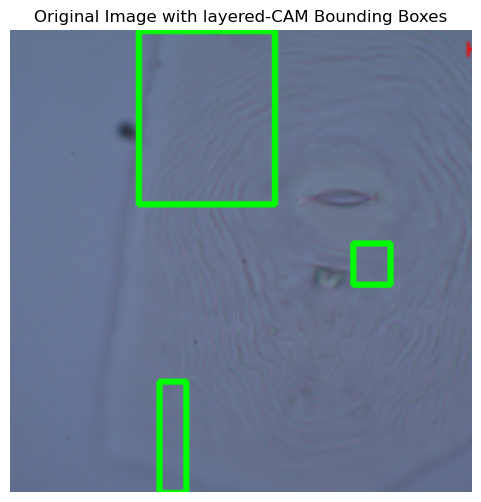

In [119]:
cam_map = grayscale_cam.copy()
cam_map = (cam_map - cam_map.min()) / (cam_map.max() - cam_map.min() + 1e-8)

threshold = 0.5   # top 15% CAM activations
binary_mask = (cam_map >= threshold).astype(np.uint8)

kernel = np.ones((9, 9), np.uint8)
binary_mask = cv2.morphologyEx(binary_mask, cv2.MORPH_CLOSE, kernel)

num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(
    binary_mask,
    connectivity=8
)

# Ensure original image is uint8
orig_img = (img_np * 255).astype(np.uint8) if img_np.max() <= 1 else img_np.copy()

boxed_img = orig_img.copy()

for i in range(1, num_labels):  # skip background
    x, y, w, h, area = stats[i]

    if area < 200:   # remove tiny noise
        continue

    cv2.rectangle(
        boxed_img,
        (x, y),
        (x + w, y + h),
        (0, 255, 0),   
        2
    )
plt.figure(figsize=(6, 6))
plt.imshow(boxed_img)
plt.axis("off")
plt.title("Original Image with layered-CAM Bounding Boxes")
plt.show()


In [120]:
# from pytorch_grad_cam.utils.model_targets import ClassifierOutputSoftmaxTarget
# from pytorch_grad_cam.metrics.cam_mult_image import CamMultImageConfidenceChange
# # Create the metric target, often the confidence drop in a score of some category
# metric_target = ClassifierOutputSoftmaxTarget(281)

# scores, batch_visualizations = CamMultImageConfidenceChange()(
#     input_tensor, 
#     inverse_cams, 
#     targets, model, 
#     return_visualization=True)
# visualization = deprocess_image(batch_visualizations[0, :])

# # State of the art metric: Remove and Debias
# from pytorch_grad_cam.metrics.road import ROADMostRelevantFirst, ROADLeastRelevantFirst

# cam_metric = ROADMostRelevantFirst(percentile=75)
# scores, perturbation_visualizations = cam_metric(
#     input_tensor, 
#     grayscale_cam, 
#     targets, model, 
#     return_visualization=True)

# # You can also average across different percentiles, and combine
# # (LeastRelevantFirst - MostRelevantFirst) / 2
# from pytorch_grad_cam.metrics.road import (ROADMostRelevantFirstAverage,
#                                           ROADLeastRelevantFirstAverage,
#                                           ROADCombined)
# cam_metric = ROADCombined(percentiles=[20, 40, 60, 80])
# scores = cam_metric(input_tensor, grayscale_cam, targets, model)

In [121]:
import cv2
import numpy as np
import torch
import torch.nn as nn
from torchvision import models, transforms
from pytorch_grad_cam import GradCAMPlusPlus
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image
from PIL import Image
import matplotlib.pyplot as plt
import os

# ---------------------------
# Image loader (your code)
# ---------------------------
def get_image(path):
    with open(os.path.abspath(path), 'rb') as f:
        with Image.open(f) as img:
            return img.convert('RGB')

img = get_image("/home/dbtproject/barsha/Image/test_set/Class1_Incognita/Meloidogyne incognita_13.jpeg")
orig_w, orig_h = img.size
orig_img_np = np.array(img) / 255.0

# ---------------------------
# Transform (your pipeline)
# ---------------------------
img_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.CenterCrop((224,224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    ),
])

input_tensor = img_transform(img).unsqueeze(0).to(device)

# ---------------------------
# Model (your setup)
# ---------------------------
model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
model.fc = nn.Linear(model.fc.in_features, 3)
model.load_state_dict(torch.load("resnet50_nematode_weights.pth", map_location=device))
model.eval().to(device)

target_layers = [model.layer4[-1]]

# ---------------------------
# Prediction
# ---------------------------
with torch.no_grad():
    outputs = model(input_tensor)
    pred_class = outputs.argmax(dim=1).item()

targets = [ClassifierOutputTarget(pred_class)]

# ---------------------------
# Grad-CAM++
# ---------------------------
with GradCAMPlusPlus(model=model, target_layers=target_layers) as cam:
    grayscale_cam = cam(
        input_tensor=input_tensor,
        targets=targets,
        aug_smooth=False,
        eigen_smooth=False
    )[0]

# ---------------------------
# INVERSE CENTER CROP
# ---------------------------
cam_256 = np.zeros((256, 256), dtype=np.float32)

start = (256 - 224) // 2
cam_256[start:start+224, start:start+224] = grayscale_cam

# ---------------------------
# RESIZE TO ORIGINAL IMAGE SIZE
# ---------------------------
cam_orig = cv2.resize(cam_256, (orig_w, orig_h))
cam_orig = np.clip(cam_orig, 0, 1)

# ---------------------------
# CLEAN NATURAL BLEND
# ---------------------------
heatmap = cv2.applyColorMap(
    np.uint8(255 * cam_orig),
    cv2.COLORMAP_JET
)
heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB) / 255.0

final_overlay = (0.6 * orig_img_np + 0.4 * heatmap)
final_overlay = np.clip(final_overlay, 0, 1)

# ---------------------------
# SHOW RESULT
# ---------------------------
plt.figure(figsize=(6,6))
plt.imshow(final_overlay)
plt.axis("off")
plt.show()


FileNotFoundError: [Errno 2] No such file or directory: 'resnet50_nematode_weights.pth'